In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

# Loading dataset
cancer_data = load_breast_cancer()

#DataFrame
df = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
df['target'] = cancer_data.target

print(f"Dataset shape: {df.shape}")
print(f"Class distribution:\n{df['target'].value_counts().rename({0: 'Malignant', 1: 'Benign'})}")

Dataset shape: (569, 31)
Class distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [18]:
# Check for missing values
missing_values = df.isnull().sum().sum()
print(f"Total missing values in dataset: {missing_values}")

# Separate features (X) and target (y)
X = df.drop('target', axis=1)
y = df['target']

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing complete: Data scaled and split successfully.")

Total missing values in dataset: 0
Preprocessing complete: Data scaled and split successfully.


In [19]:
# Import the five required classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Dictionary containing all models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "k-Nearest Neighbors": KNeighborsClassifier()
}

# Train and evaluate each model
evaluation_results = []

for name, model in models.items():
    # Fit model on scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

    evaluation_results.append({
        "Algorithm": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Convert results to a DataFrame for clean comparison
results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

print("Model Performance Summary:")
display(results_df)

Model Performance Summary:


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111
1,Support Vector Machine,0.982456,0.986111,0.986111,0.986111
2,Random Forest,0.956140,0.958904,0.972222,0.965517
3,k-Nearest Neighbors,0.956140,0.958904,0.972222,0.965517
4,Decision Tree,0.912281,0.955882,0.902778,0.928571


/tmp/ipykernel_1836/1412731211.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Accuracy", y="Algorithm", data=results_df, palette="viridis")


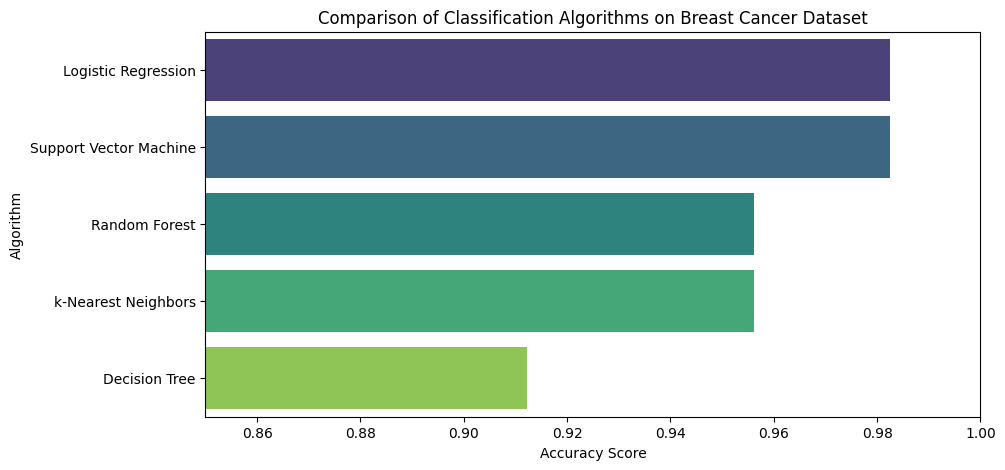

In [20]:
# Plotting the accuracy of the models
plt.figure(figsize=(10, 5))
sns.barplot(x="Accuracy", y="Algorithm", data=results_df, palette="viridis")
plt.title("Comparison of Classification Algorithms on Breast Cancer Dataset")
plt.xlabel("Accuracy Score")
plt.ylabel("Algorithm")
plt.xlim(0.85, 1.0)
plt.show()